# Notebook 35 — Figures of the revised manuscript

**Author:** Sunita Sahu · **Revision item:** §11 figures (rebuilt last), decision D11 (house style) · CPU only

**Purpose.** Rebuild every figure of the submitted paper from the revised measurements, add the three new figures of the revision, and draft a caption for each. The figure plan is `paper/Pending_Manuscript_Edits.md` §11 (with the caption items E-4.3g, E-4.5d, E-5.4b and E-5.8d). Numbering follows the submitted paper (Figures 1–9); the new figures are N1–N3.

**Inputs** (`outputs/measurements/`): `nb26_parameter_components_v2.csv`, `nb26_trainable_share_v2.csv`, `nb27_table3_v2_{448,1024}.csv`, `nb27_table4_tokens_v2.csv`, `nb27_table7_v2.csv`, `nb28_table6_v2.csv`, `nb28_table8_v2.csv`, `nb28_efficiency_*_{448,1024}.csv`, `nb31_latency_table.csv`, `nb31_prefill_floor.csv`, `nb31_decode_versus_operator_calls.csv`, `nb32_compute_by_side.csv`, `nb32_growth_summary.csv`, `nb32_latency_agreement.csv`. Model names, families and release years come from `vlm_audit/roster_metadata.py`. No number is typed into the code: a loader stops with an error when an expected model or column is missing.

**Outputs** (`outputs/figures/revised/`): one vector PDF and one 300-dpi PNG per figure, saved at their exact size (6.75 in text width or 3.25 in column width, 8 pt text), and `figure_captions.md` (draft captions).

**House style (proposal for the open decision D11).** Okabe–Ito colour-blind-safe palette keyed to the architecture family, with one marker shape per family so that families stay distinguishable in greyscale; no titles inside the images; log axes where values span orders of magnitude. The style is defined once in `revised_figures.HOUSE_STYLE`, `FAMILY_COLOURS` and `FAMILY_MARKERS`.

**How to re-run.** Run after notebooks 26–28 and 31–33 (and after notebook 32 whenever notebook 31 changes). Then run this notebook top to bottom; it overwrites the files in `outputs/figures/revised/`.

---
## Setup

In [1]:
# The module draws without pyplot; the inline backend shows its figures (at 150 dpi) in this notebook.
%matplotlib inline
import sys
from pathlib import Path
from IPython.display import Markdown, display

NOTEBOOK_DIR = Path.cwd()
CODE_ACTIVE = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
sys.path.insert(0, str(CODE_ACTIVE))
MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
FIGURE_DIR = CODE_ACTIVE / 'outputs' / 'figures' / 'revised'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

from vlm_audit import revised_figures
from vlm_audit.roster_metadata import ROSTER_ORDER

print(f'{len(ROSTER_ORDER)} models; {len(revised_figures.FIGURES)} figures -> '
      f'{FIGURE_DIR.relative_to(CODE_ACTIVE)}')

23 models; 13 figures -> outputs\figures\revised


---
## Figure 1 — Per-component parameter breakdown

100%-stacked bars of vision, fusion, language-model and output-head parameters per model, sorted by vision share. Chameleon (decision D4: no V/F/L decomposition) sits below the others, hatched.

outputs\figures\revised\fig01_parameter_breakdown.pdf
outputs\figures\revised\fig01_parameter_breakdown.png


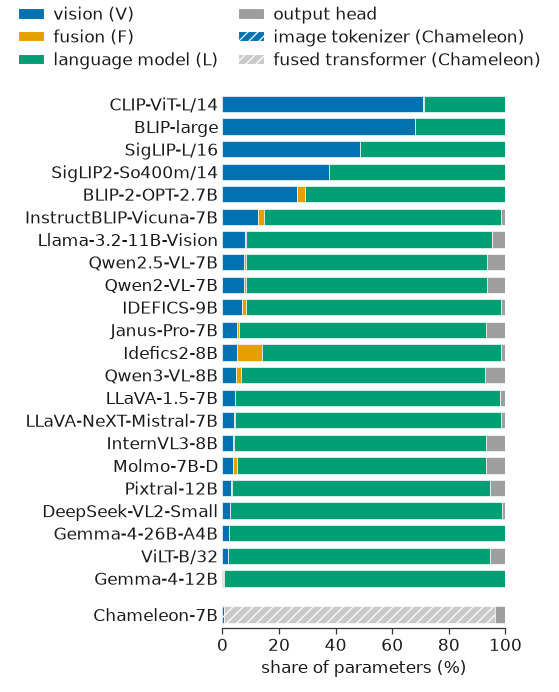

In [2]:
figure = revised_figures.plot_parameter_breakdown(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig01_parameter_breakdown', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 2 — Forward-compute decomposition at 1,024²

Left: each component's share of the forward compute (vision encoder, fusion, language model over visual tokens, language model over text tokens, output head). Right: total compute on a log axis, filled at 1,024², hollow at 448². Sorted by total. Replaces the submitted caption claim E-4.3g, which fails for Llama-3.2-Vision and Idefics2.

outputs\figures\revised\fig02_compute_decomposition.pdf
outputs\figures\revised\fig02_compute_decomposition.png


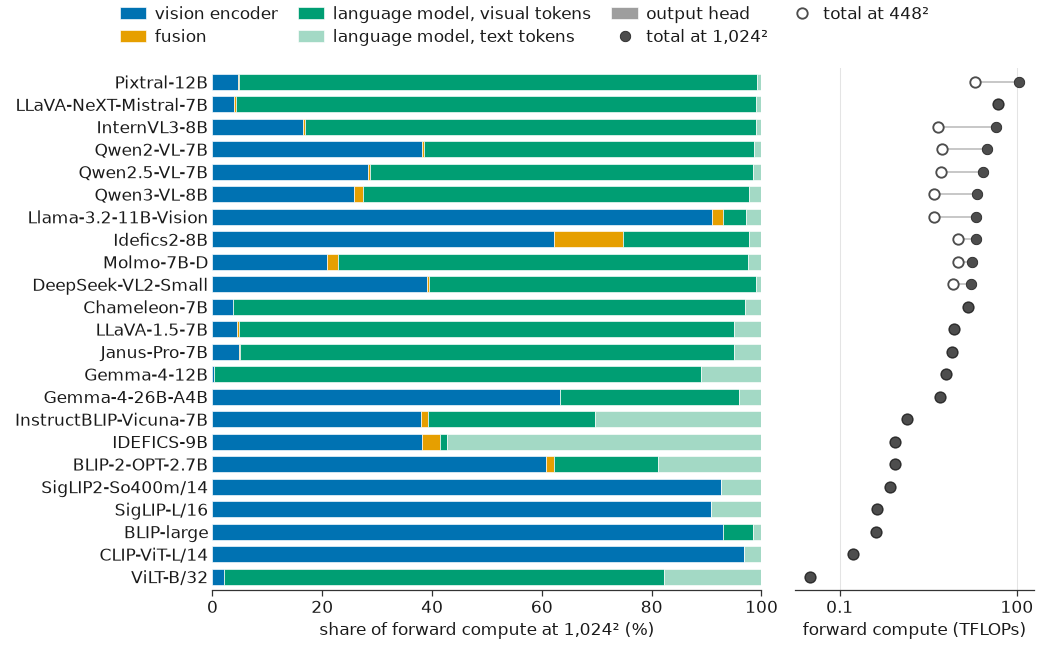

In [3]:
figure = revised_figures.plot_compute_decomposition(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig02_compute_decomposition', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 3 — Bandwidth census

Visual tokens at the fusion boundary at 448², 1,024² and the released maximum, log axis.

outputs\figures\revised\fig03_bandwidth_census.pdf
outputs\figures\revised\fig03_bandwidth_census.png


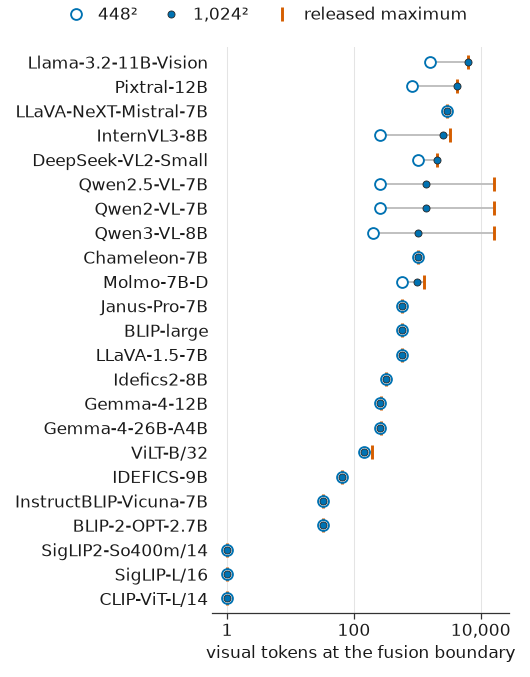

In [4]:
figure = revised_figures.plot_bandwidth_census(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig03_bandwidth_census', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 4 — Trainable share by release year

One column per model, grouped by release year, marked by the four regimes of Table 5 (E-4.5d). Qwen3-VL's share is not reported by its source and sits on a separate row.

outputs\figures\revised\fig04_trainable_share_by_year.pdf
outputs\figures\revised\fig04_trainable_share_by_year.png


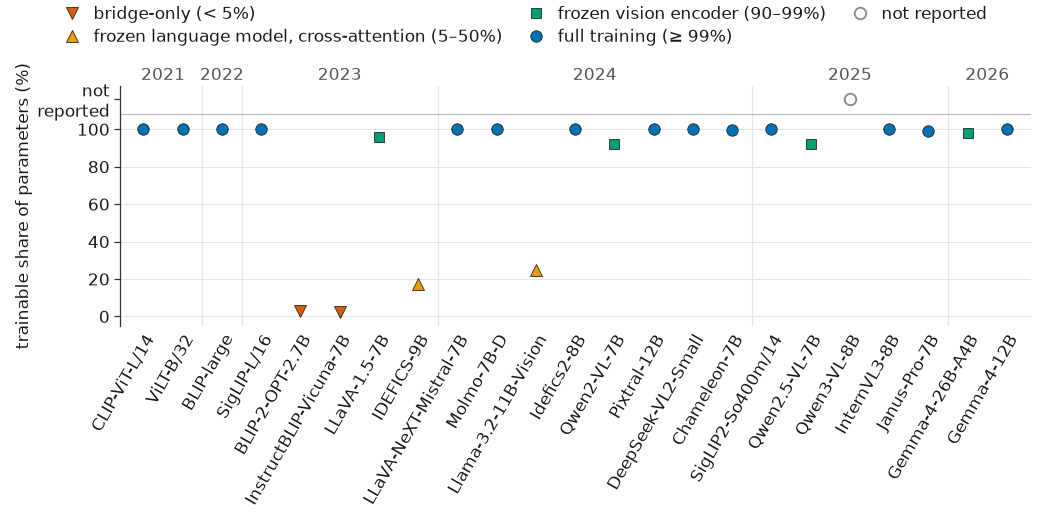

In [5]:
figure = revised_figures.plot_trainable_share_by_year(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig04_trainable_share_by_year', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 5 — Vision-to-language parameter ratio by release year and family

V/L per model (log axis), family colours and markers; dashed parity line at 1, light lines at 0.5 and 0.10.

outputs\figures\revised\fig05_vision_language_ratio_by_year.pdf
outputs\figures\revised\fig05_vision_language_ratio_by_year.png


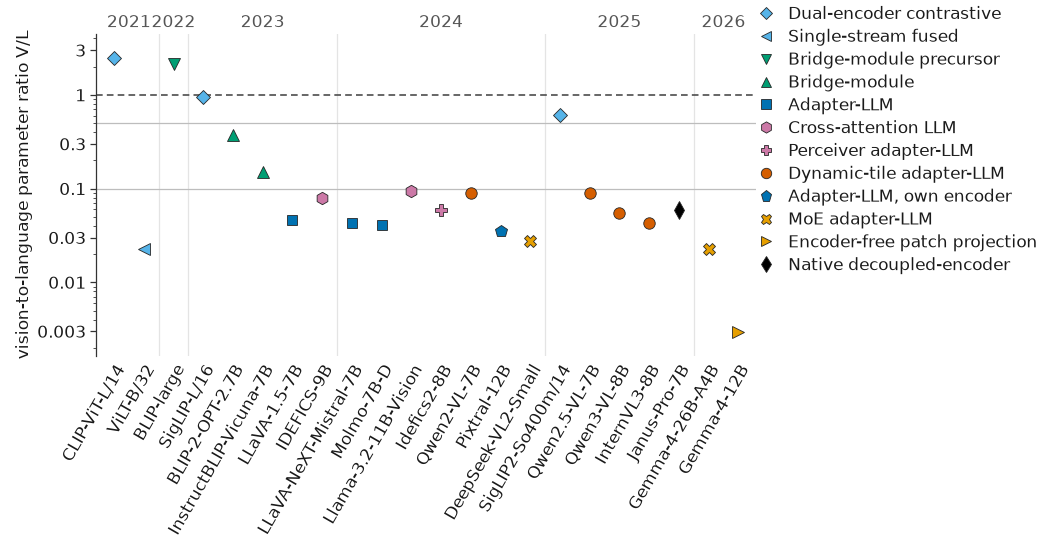

In [6]:
figure = revised_figures.plot_vision_language_ratio_by_year(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig05_vision_language_ratio_by_year', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 6 — Vision compute share against vision parameter share

C_V% against V% (log–log); filled at 1,024², hollow at 448², joined where they differ; dashed equal-share line; the models discussed in the text are labelled.

outputs\figures\revised\fig06_vision_compute_vs_parameter_share.pdf
outputs\figures\revised\fig06_vision_compute_vs_parameter_share.png


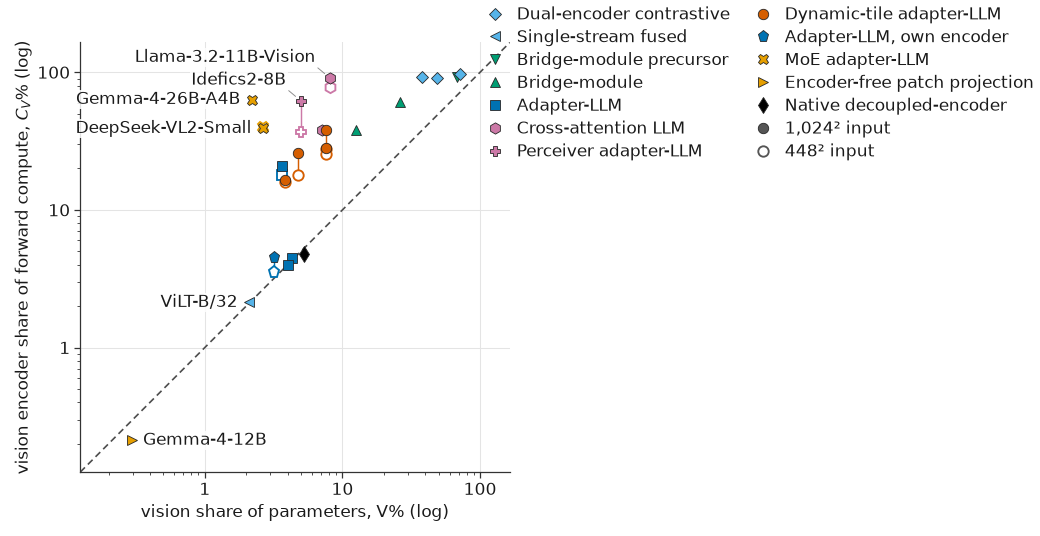

In [7]:
figure = revised_figures.plot_vision_compute_versus_parameter_share(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig06_vision_compute_vs_parameter_share', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 7 — Benchmark score against visual tokens at 1,024²

One panel per benchmark of the correlation grid with at least seven scored models, n in each panel, no fitted curves (E-5.4b).

outputs\figures\revised\fig07_score_vs_visual_tokens.pdf
outputs\figures\revised\fig07_score_vs_visual_tokens.png


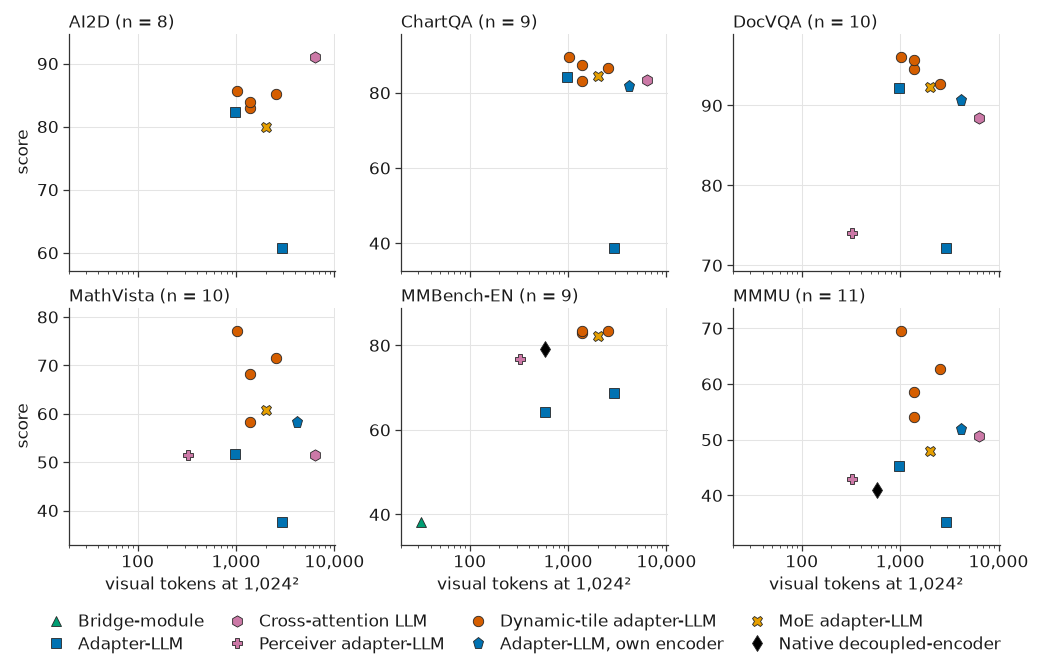

In [8]:
figure = revised_figures.plot_score_versus_visual_tokens(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig07_score_vs_visual_tokens', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 8 (supplement) — Marginal and year-partial Spearman ρ

Seven predictors × seven benchmarks: marginal ρ with its 95% interval where available, and ρ partial on release year. Proposed for the supplement (decision D6).

outputs\figures\revised\fig08_correlation_grid_supplement.pdf
outputs\figures\revised\fig08_correlation_grid_supplement.png


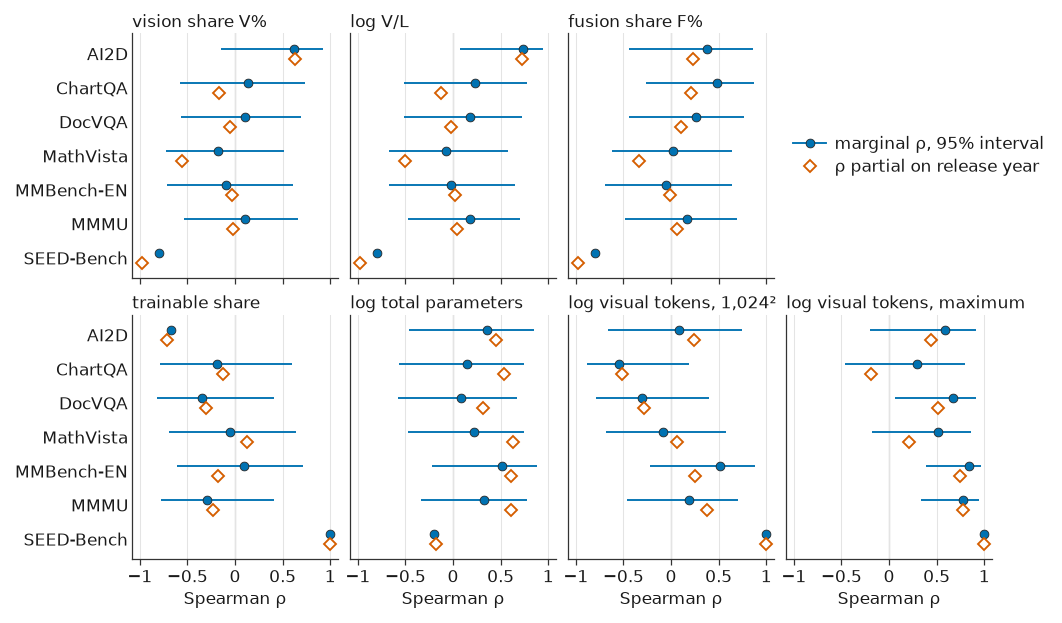

In [9]:
figure = revised_figures.plot_correlation_grid(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig08_correlation_grid_supplement', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 9a — Composite score against compute (Section 5.8)

Composite score against forward compute (log), at 1,024² and 448², with the Pareto frontier; n benchmarks per model in parentheses.

outputs\figures\revised\fig09a_efficiency_composite.pdf
outputs\figures\revised\fig09a_efficiency_composite.png


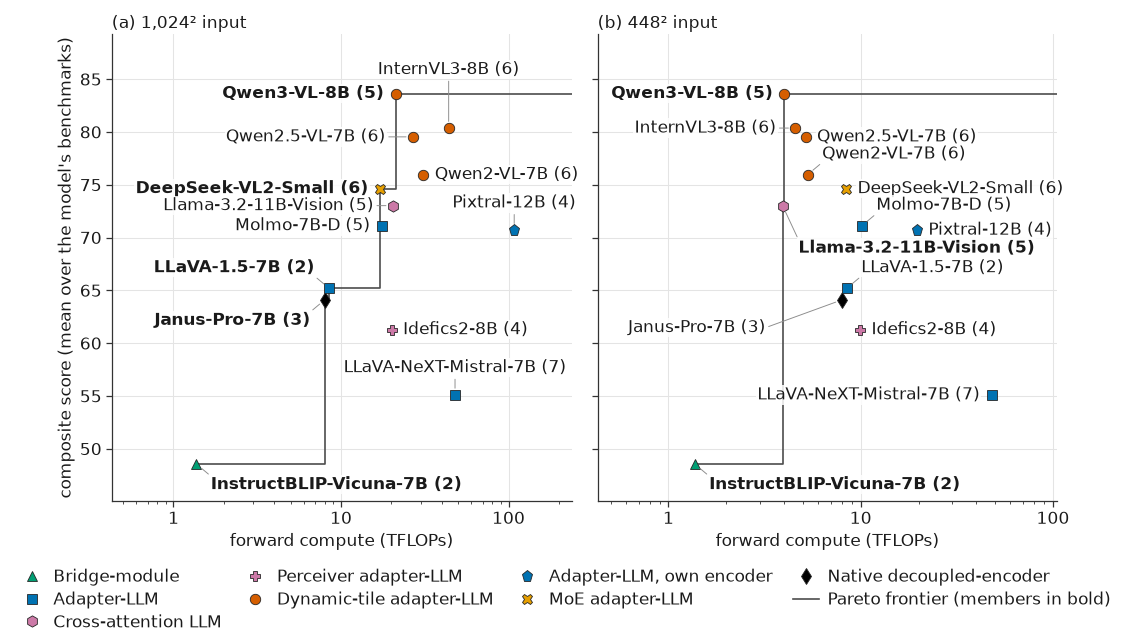

In [10]:
figure = revised_figures.plot_efficiency_composite(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig09a_efficiency_composite', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure 9b — DocVQA and MMMU against compute at 1,024² (Section 5.8)

One benchmark per panel, with the Pareto frontier (E-5.8d).

outputs\figures\revised\fig09b_efficiency_docvqa_mmmu.pdf
outputs\figures\revised\fig09b_efficiency_docvqa_mmmu.png


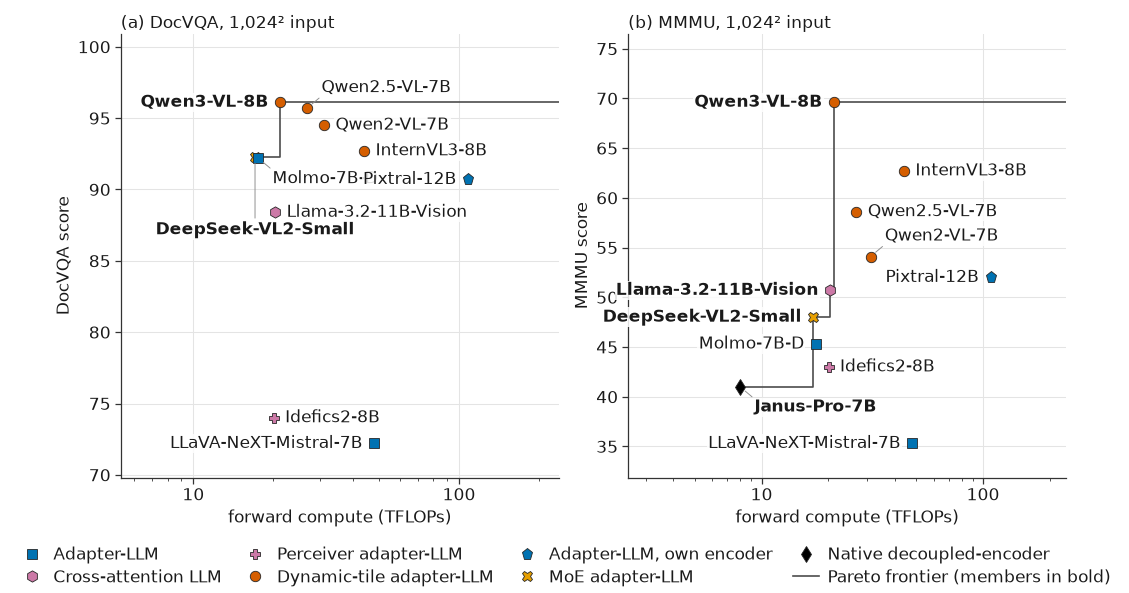

In [11]:
figure = revised_figures.plot_efficiency_single_benchmarks(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'fig09b_efficiency_docvqa_mmmu', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure N1 (new, central) — Compute against input size

The two panels of notebook 32: total compute against the image side (log–log; every model's intrinsic curve, executed curves dashed where they differ, the two GPU-measured inputs dotted) and C_V against the side. Image-independent models in grey; the others in family colours with direct labels.

outputs\figures\revised\figN1_compute_vs_input_size.pdf
outputs\figures\revised\figN1_compute_vs_input_size.png


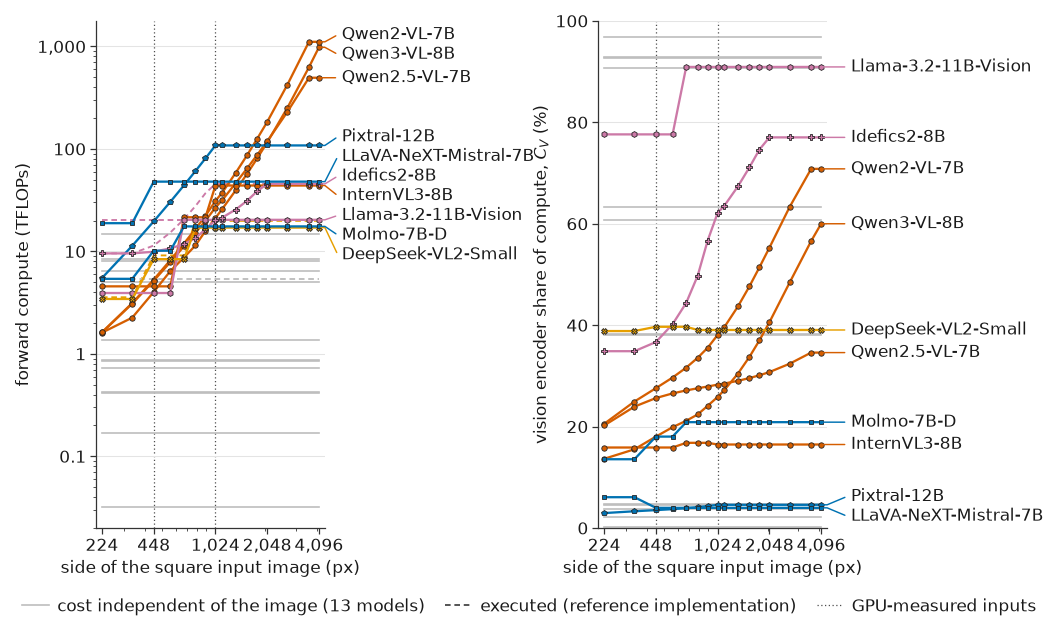

In [12]:
figure = revised_figures.plot_compute_versus_input_size(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'figN1_compute_vs_input_size', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure N2 (new) — Prefill latency against executed FLOPs

Measured prefill latency (notebooks 29–31, 34) against the FLOPs the reference implementation executes, log–log, both inputs, coloured by family.

outputs\figures\revised\figN2_latency_vs_flops.pdf
outputs\figures\revised\figN2_latency_vs_flops.png


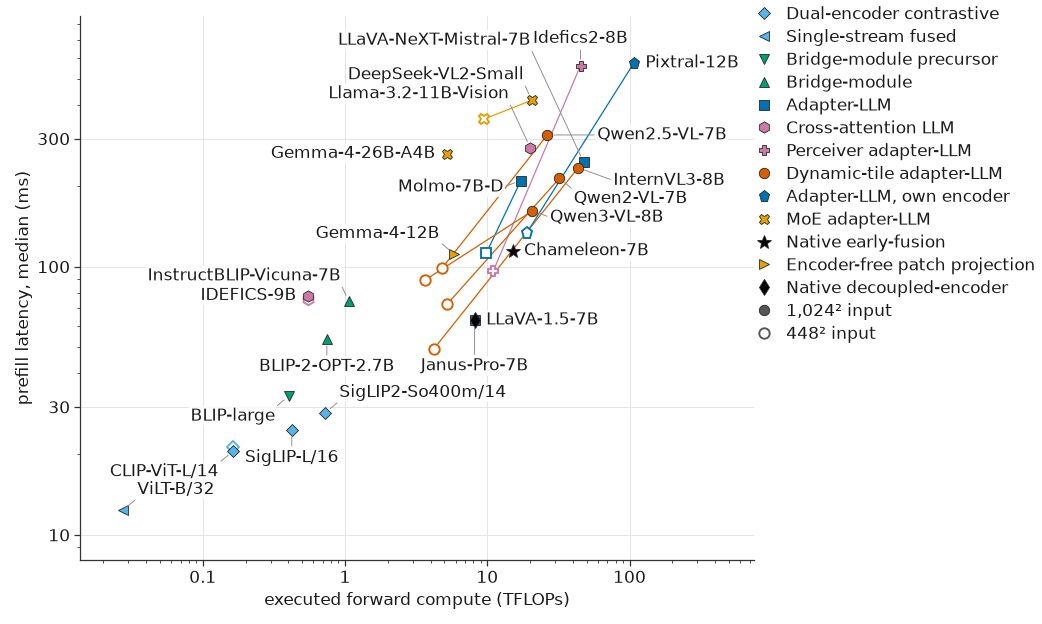

In [13]:
figure = revised_figures.plot_latency_versus_flops(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'figN2_latency_vs_flops', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Figure N3 (new) — The per-pass latency floor

(a) Language-model prefill time in decode steps against the tokens the language model sees (log x), lines at 1 and 1.2 decode steps, mixture-of-experts models hollow. (b) Decode time per token against operator calls per decode step, with the least-squares line.

outputs\figures\revised\figN3_latency_floor.pdf
outputs\figures\revised\figN3_latency_floor.png


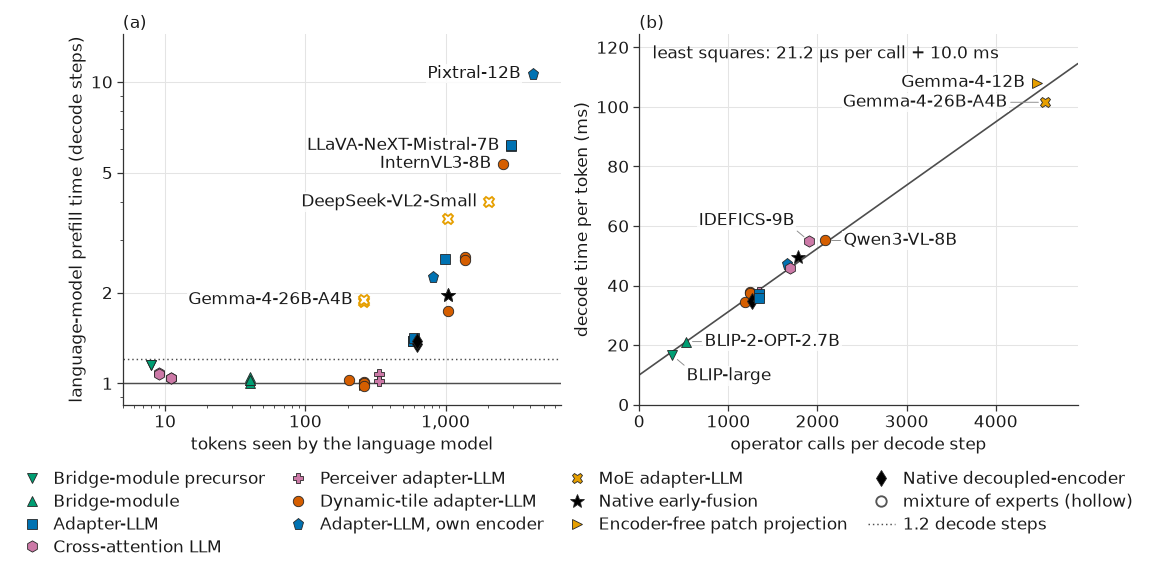

In [14]:
figure = revised_figures.plot_latency_floor(MEASUREMENT_DIR)
written = revised_figures.save_figure(figure, 'figN3_latency_floor', FIGURE_DIR)
print('\n'.join(str(path.relative_to(CODE_ACTIVE)) for path in written))
display(figure)

---
## Draft captions

One caption per figure, with every number computed from the tables above. Written to `outputs/figures/revised/figure_captions.md`; Figure 8 is marked as supplementary.

In [15]:
captions_text = revised_figures.captions_markdown(MEASUREMENT_DIR)
captions_path = FIGURE_DIR / 'figure_captions.md'
captions_path.write_text(captions_text, encoding='utf-8')
print(f'wrote {captions_path.relative_to(CODE_ACTIVE)}')
display(Markdown(captions_text))

wrote outputs\figures\revised\figure_captions.md


# Draft figure captions (revised manuscript)

Generated by notebook 35 (`vlm_audit/revised_figures.py`) from the measurement tables of notebooks 26–28 and 31–33; every number is recomputed on each run. Figures are in this folder as PDF (vector) and PNG (300 dpi). `$C_V$` is the vision encoder's share of forward compute.

Author: Sunita Sahu.

## Figure 1: `fig01_parameter_breakdown`

Parameters by component (vision encoder V, fusion F, language model L, untied output head) as shares of each model's total, for the 22 models with a separable decomposition, sorted by vision share. V% runs from 70.9% (CLIP-ViT-L/14) to 0.29% (Gemma-4-12B). Fusion takes less than 3% of the parameters in 21 of 22 models; the largest fusion share is 8.8% (Idefics2-8B). Chameleon-7B has no vision/fusion/language decomposition (decision D4) and is drawn below the others, hatched: its 29.4 M-parameter image tokenizer as vision and its 6,745 M-parameter fused transformer as one block. Gemma-4-12B's 2.5 M audio-encoder parameters (0.02%) are not drawn. The roster includes the 3 models added in this revision (Qwen3-VL-8B, Gemma-4-12B and Gemma-4-26B-A4B).

## Figure 2: `fig02_compute_decomposition`

Forward compute on the common 1,024² input, by component (left, share of each model's total) and in total (right, log scale; hollow: the 448² input), models sorted by total. Totals run from 31.9 GFLOPs (ViLT-B/32) to 108.2 TFLOPs (Pixtral-12B); 14 models cost the same at both inputs. The language model processing visual tokens is the largest component in 13 of 23 models; the vision encoder is the largest in 9 (CLIP-ViT-L/14 96.7%, BLIP-large 93.0%, SigLIP2-So400m/14 92.7%, Llama-3.2-11B-Vision 90.9%, SigLIP-L/16 90.8%, Gemma-4-26B-A4B 63.3%, Idefics2-8B 62.1%, BLIP-2-OPT-2.7B 60.7%, InstructBLIP-Vicuna-7B 38.0%). Chameleon's encoder is its VQ image tokenizer; in models without a decoder language model the language columns hold the text-side transformer. The output head is charged at one position.

## Figure 3: `fig03_bandwidth_census`

Visual tokens at the fusion boundary of each model through its released preprocessing: at 448² (hollow), at 1,024² (filled) and at the released maximum (bar), log scale, sorted by the 1,024² count. At 1,024² the counts run from 1 (CLIP-ViT-L/14, SigLIP-L/16 and SigLIP2-So400m/14) to 6,404 (Llama-3.2-11B-Vision); the released maximum reaches 16,386 (Qwen3-VL-8B, Qwen2-VL-7B and Qwen2.5-VL-7B). The count depends on the input image for 11 of 23 models, 8 of which differ between the two common inputs.

## Figure 4: `fig04_trainable_share_by_year`

Trainable share of parameters in each model's final training stage, models grouped by release year and marked by the four regimes of Table 5: bridge-only (2.4–2.9%, 2 models, 2023); frozen language model, cross-attention (17.5–24.7%, 2 models, 2023–2024); frozen vision encoder (92.4–97.8%, 4 models, 2023–2026); full training (99.0–100.0%, 14 models, 2021–2026). The share of Qwen3-VL-8B is not reported by its source and is shown on the separate top row.

## Figure 5: `fig05_vision_language_ratio_by_year`

Vision-to-language parameter ratio V/L by release year and family, log scale; dashed: parity (V/L = 1); light lines: 0.5 and 0.10. V/L runs from 2.46 (CLIP-ViT-L/14) to 0.003 (Gemma-4-12B), a 834-fold range. Models per band: above parity: 2 (CLIP-ViT-L/14 and BLIP-large); 0.5–1: 2 (SigLIP-L/16 and SigLIP2-So400m/14); 0.10–0.5: 2 (BLIP-2-OPT-2.7B and InstructBLIP-Vicuna-7B); below 0.10: 16 (of 22). Chameleon-7B is omitted (no V/L decomposition, decision D4).

## Figure 6: `fig06_vision_compute_vs_parameter_share`

Vision encoder share of forward compute ($C_V$%) against vision share of parameters (V%), log–log, for the 22 models with a V/F/L decomposition; filled: 1,024², hollow: 448², joined where they differ; dashed: equal shares. Spearman ρ = +0.72 at 1,024² and +0.74 at 448² (n = 22). The ratio $C_V$%/V% at 1,024² runs from 0.72 (Gemma-4-12B) to 28.7 (Gemma-4-26B-A4B); 19 models lie above the equal-share line. Chameleon-7B is omitted (decision D4).

## Figure 7: `fig07_score_vs_visual_tokens`

Benchmark score against visual tokens at the fusion boundary at 1,024² (log scale), one panel per benchmark of the correlation grid with at least 7 scored models: AI2D (n = 8), ChartQA (n = 9), DocVQA (n = 10), MathVista (n = 10), MMBench-EN (n = 9), MMMU (n = 11). Omitted for too few scores: SEED-Bench (n = 4). VQAv2 is reported descriptively in Table 6 and is not part of the grid. No curves are fitted: with at most 11 models per benchmark and token count confounded with release year, a saturation or changepoint fit is not identifiable.

## Figure 8 (supplement): `fig08_correlation_grid_supplement`

Supplement. Marginal Spearman ρ (filled, with its 95% interval where n ≥ 8) and ρ partial on release year (hollow) for 7 predictors × 7 benchmarks (49 tests). 4 of 49 marginal tests have an unadjusted permutation p < 0.05; the smallest Benjamini–Hochberg-adjusted p is 0.18 (marginal) and 0.33 (partial), the smallest Benjamini–Yekutieli-adjusted p 0.79. n per benchmark: AI2D 8, ChartQA 9, DocVQA 10, MathVista 10, MMBench-EN 9, MMMU 11, SEED-Bench 4. For trainable share n is lower where a scored model's share is unreported: AI2D 7, ChartQA 8, DocVQA 9, MathVista 9, MMMU 10.

## Figure 9a: `fig09a_efficiency_composite`

Composite score (the mean of each model's scores on the 7 benchmarks of the grid, over the 2–7 it reports; n in parentheses) against forward compute, log scale, at the 1,024² (a) and 448² (b) inputs. Line: Pareto frontier (no other model has an equal or higher score at equal or lower compute); members in bold. Frontier at 1,024²: InstructBLIP-Vicuna-7B, Janus-Pro-7B, LLaVA-1.5-7B, DeepSeek-VL2-Small and Qwen3-VL-8B; at 448²: InstructBLIP-Vicuna-7B, Llama-3.2-11B-Vision and Qwen3-VL-8B; on both: InstructBLIP-Vicuna-7B and Qwen3-VL-8B. Scores run from 48.5 to 83.6; compute at 1,024² from 1.37 to 108.2 TFLOPs, and score per TFLOP from 0.65 to 35.4 (54×). Composites average different benchmark subsets, so they rank models only roughly.

## Figure 9b: `fig09b_efficiency_docvqa_mmmu`

DocVQA (a, 10 models) and MMMU (b, 11 models) score against forward compute at 1,024², log scale, with the Pareto frontier (members in bold): DocVQA DeepSeek-VL2-Small and Qwen3-VL-8B; MMMU Janus-Pro-7B, DeepSeek-VL2-Small, Llama-3.2-11B-Vision and Qwen3-VL-8B. Pixtral-12B uses 4.0× the compute of Qwen2.5-VL-7B at 1,024² (3.8× at 448²) for a lower DocVQA score (90.7 against 95.7).

## Figure N1 (new, central): `figN1_compute_vs_input_size`

Forward compute (left, TFLOPs, log–log) and the vision encoder's share of it, $C_V$ (right), against the side of a square input image from 224 to 4,096 px, priced through each model's released preprocessing with 32 prompt tokens. Grey: the 13 models whose cost does not depend on the image; coloured and labelled: the 10 whose cost grows with it until a plateau set by their preprocessing, reached between 448 and 4,096 px; the plateau is 2.5× (LLaVA-NeXT-Mistral-7B) to 684× (Qwen2-VL-7B) the cost at 224 px. Dashed: compute executed by the reference implementation where it differs from the intrinsic count by more than 1% (Llama-3.2-11B-Vision, Idefics2-8B, DeepSeek-VL2-Small and Gemma-4-26B-A4B). Dotted: the two inputs measured on the GPU (448² and 1,024²); between them the executed compute ratio ranks the measured latency ratios with Spearman ρ = +0.82 (n = 23).

## Figure N2 (new): `figN2_latency_vs_flops`

Median prefill latency (batch size 1, NVIDIA A100-SXM4-80GB) against the forward FLOPs the reference implementation executes, log–log, for all 23 models; filled: 1,024², hollow: 448², joined where they differ. Spearman ρ = +0.87 at 1,024² and +0.81 at 448² (n = 23 each). Within one model the latency changes by up to 5.8× between the two inputs (Idefics2-8B).

## Figure N3 (new): `figN3_latency_floor`

(a) Language-model prefill time in units of one decode step against the tokens the language model sees, log–log (38 measurements over both inputs). Solid: one decode step; dotted: 1.2 decode steps. 18 of 34 dense measurements lie within 1.2 steps (0.98–1.15). Every dense measurement with at most 334 tokens is on this floor and every one from 585 tokens is above it. Hollow: mixture-of-experts language models (DeepSeek-VL2-Small and Gemma-4-26B-A4B), whose prefill reaches more experts than a decode step. (b) Decode time per token against operator calls per decode step (n = 17); least-squares line 21.2 µs per call + 10.0 ms (Pearson r = 0.995); labelled: the models outside the 10th–80th percentiles of the call count. Library releases: transformers 4.57.6 (15 models), transformers 5.18.0 (2 models).


---
## Check: every figure written

In [16]:
expected = [FIGURE_DIR / f'{name}.{extension}' for name, _, _, _ in revised_figures.FIGURES
            for extension in ('pdf', 'png')]
missing = [path.name for path in expected if not path.exists()]
assert not missing, f'figures not written: {missing}'
print(f'{len(expected)} files present in {FIGURE_DIR.relative_to(CODE_ACTIVE)}, plus figure_captions.md')

26 files present in outputs\figures\revised, plus figure_captions.md
